In [4]:
# Task 1 — Data Import & Setup

# Step 1: Import the required libraries
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/social_media_engagement_5000.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!




*   import pandas as pd - Imports the Pandas library, which is used to load, organise, clean, and analyse data
*   import numpy as np - Imports the NumPy library, which is used for numerical calculations and array operations
*   url = "..." - Stores the GitHub CSV file link in a variable named url
*   df = pd.read_csv(url) - Reads the CSV file from the given URL and stores the data in a Pandas DataFrame named df
*   print("Dataset loaded successfully!") - Displays a confirmation message after loading the dataset





In [5]:
# Step 2: Display the first five rows
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372




*   df represents the dataset
*   head() displays the first five rows of the dataset
*   It helps us understand the structure and contents of the dataset




In [7]:
# Step 3: Check the dataset structure
df.shape

(5000, 19)


*   shape is used to find the number of rows and columns

*   5000 represents the number of rows
*   19 represents the number of columns






In [8]:
# Step 4: Check the column names
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

The columns function displays all column names in the dataset.
The dataset contains columns such as:

*   user_id, age, gender, post_type, likes, comments, shares, posted_at, engagement_rate

   
   



In [9]:
# Step 5: Check the data types
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


The dtypes function displays the data type of each column.

*   int64 - Integer numbers
*   float64 - Decimal numbers
*   object - Text values
*   bool - True or False values





In [10]:
# Step 6: Convert the date column into datetime format
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y'
)

print(df['posted_at'].dtype)

datetime64[ns]


 The dataset contains a date column named posted_at.

*   pd.to_datetime() converts the date column into datetime format
*   format='%d-%m-%Y' specifies the date format as day-month-year
  





In [11]:
# Step 7: Use NumPy arrays for basic operations
likes_array = df['likes'].dropna().to_numpy()

print("Likes Array:")
print(likes_array)

print("Total Likes:", np.sum(likes_array))
print("Average Likes:", np.mean(likes_array))
print("Maximum Likes:", np.max(likes_array))
print("Minimum Likes:", np.min(likes_array))

Likes Array:
[ 7011. 11750.  4862. ... 13487. 16894. 14830.]
Total Likes: 49019162.0
Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0




*   to_numpy() converts the likes column into a NumPy array
*   np.sum() calculates the total likes
*   np.mean() calculates the average likes
*   np.max() finds the maximum likes
*   np.min() finds the minimum likes
*   dropna() excludes missing values from the calculations



In [12]:
# Task 2 — Data Cleaning

# Step 1: Check missing values using isnull()
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150




*   isnull() identifies missing values
*   sum() counts the missing values in each column



In [13]:
# Step 2: Check missing values using isna()
df.isna().sum()


,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


isna() also identifies missing values. It performs the same task as isnull().

In [15]:
# Step 3: Handle missing values using dropna()
df_dropna = df.dropna()

print("Original rows:", len(df))
print("Rows after dropna:", len(df_dropna))

Original rows: 5000
Rows after dropna: 4162




*   dropna() removes rows containing at least one missing value
*   df_dropna is used to keep the original dataset unchanged



In [16]:
# Step 4: Handle missing values using fillna()
df_fill = df.copy()

df_fill['age'] = df_fill['age'].fillna(
    df_fill['age'].median()
)

print("Missing age values:", df_fill['age'].isna().sum())

Missing age values: 0




*   copy() creates a separate copy of the dataset
*   median() calculates the middle value of the age column
*   fillna() replaces missing age values with the median




In [17]:
# Step 5: Handle missing numerical values using median
df_clean = df.copy()

numeric_cols = ['age', 'likes', 'comments', 'shares']

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

print(df_clean[numeric_cols].isna().sum())

age         0
likes       0
comments    0
shares      0
dtype: int64




*   numeric_cols contains the numerical columns
*   The for loop processes each column
*   median() calculates the median value
*   fillna() replaces missing values



In [18]:
# Step 6: Handle missing categorical values using mode
categorical_cols = ['gender', 'sentiment']

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

print(df_clean[categorical_cols].isna().sum())

gender       0
sentiment    0
dtype: int64




*   mode() finds the most frequently occurring value
*   [0] selects the first mode
*   fillna() replaces missing categorical values with the most frequent value




In [19]:
# Step 7: Handle missing values using forward-fill
df_forward = df[['age', 'gender']].head(10).copy()

df_forward = df_forward.ffill()

display(df_forward)

,age,gender
0,43.0,Female
1,33.0,Male
2,32.0,Female
3,51.0,Other
4,34.0,Other
5,16.0,Other
6,25.0,Male
7,57.0,Female
8,54.0,Female
9,62.0,Female


Forward-fill replaces missing values with the previous available value.

*   ffill() means forward-fill
*   It fills a missing value using the previous row's value
*   used a small sample to demonstrate this method




In [20]:
# Step 8: Handle missing values using backward-fill
df_backward = df[['age', 'gender']].head(10).copy()

df_backward = df_backward.bfill()

display(df_backward)

,age,gender
0,43.0,Female
1,33.0,Male
2,32.0,Female
3,51.0,Other
4,34.0,Other
5,16.0,Other
6,25.0,Male
7,57.0,Female
8,54.0,Female
9,62.0,Female


Backward-fill replaces missing values with the next available value.

*   bfill() means backward-fill
*   It fills a missing value using the next row's value
  





In [21]:
# Step 9: Check duplicate records
df_clean.duplicated().sum()

np.int64(0)



*   df.duplicated() checks for duplicate rows in the dataset
*   .sum() counts the duplicate rows
*   np.int64(0) means there are zero duplicate rows in your dataset




In [22]:
# Step 10: Remove duplicate records
df_clean = df_clean.drop_duplicates()

print("Duplicates after removal:", df_clean.duplicated().sum())

Duplicates after removal: 0


drop_duplicates() removes repeated rows from the dataset

In [23]:
# Step 11: Standardize categorical values
text_cols = [
    'gender',
    'country',
    'post_type',
    'post_category',
    'device_type',
    'sentiment'
]

for col in text_cols:
    df_clean[col] = (
        df_clean[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

print(df_clean['gender'].unique())
print(df_clean['sentiment'].unique())

['female' 'male' 'other']
['negative' 'positive' 'neutral']




*   astype(str) converts values into strings
*   str.strip() removes extra spaces
*   str.lower() converts text into lowercase
*  unique() displays the distinct values



In [24]:
# Step 12: Check unrealistic values in likes, comments, and shares
print("Negative likes:", (df_clean['likes'] < 0).sum())

print("Negative comments:", (df_clean['comments'] < 0).sum())

print("Negative shares:", (df_clean['shares'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0




*   The condition < 0 checks for negative values
*   sum() counts how many negative values exist



In [25]:
# Step 13: Extract hashtag count
import re

df_clean['hashtag_count'] = df_clean['hashtags'].fillna('').apply(
    lambda x: len(re.findall(r'#\w+', str(x)))
)

display(df_clean[['hashtags', 'hashtag_count']].head())

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1




*   re.findall() finds all hashtags in the text
*   len() counts the hashtags
*   apply() performs the operation on every row
*   hashtag_count stores the result in a new column



In [26]:
# Step 14: Clean sentiment labels
df_clean['sentiment'] = (
    df_clean['sentiment']
    .str.replace(r'[^a-z\s]', '', regex=True)
    .str.strip()
)

print(df_clean['sentiment'].unique())

['negative' 'positive' 'neutral']




*   str.replace() removes unwanted characters
*   str.strip() removes extra spaces
*   unique() displays the cleaned sentiment categories




In [27]:
# Step 15: Verify the cleaned dataset
print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

Dataset shape: (5000, 20)

Missing values:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtag_count       0
dtype: int64

Duplicate records:
0


This final check confirms that the missing values have been handled and duplicate records have been removed.

In [28]:
# Task 3 — Data Exploration using Pandas

# Step 1: Display the first five rows
df_clean.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


 df_clean.head() displays the first five records.

In [29]:
# Step 2: Display the last five rows
df_clean.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


df_clean.tail() displays the last five records.

In [30]:
# Step 4: Display column names
df_clean.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

df_clean.columns displays all column names.

In [31]:
# Step 5: Check dataset information
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

Displays column names, data types, non-null values, and memory usage.

In [32]:
# Step 6: Check data types
df_clean.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


df_clean.dtypes displays the data type of every column.

In [33]:
# Step 7: Generate summary statistics
df_clean.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


Calculates count, mean, standard deviation, minimum, maximum, and quartiles for numerical columns.

In [34]:
# To include categorical columns too:
df_clean.describe(include='all')

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000,5000,5000,5000,5000.000000,5000.000000
unique,NaN,NaN,3,10,NaN,4,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3,3,761,NaN,NaN
top,NaN,NaN,male,india,NaN,reel,fitness,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,mobile,positive,#tech,NaN,NaN
freq,NaN,NaN,1849,535,NaN,1283,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4517,1684,2513,201,NaN,NaN
mean,54561.890800,38.440400,NaN,NaN,548042.909000,NaN,NaN,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,NaN,NaN,NaN,NaN,0.964356,1.998600
min,10055.000000,13.000000,NaN,NaN,100068.000000,NaN,NaN,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,NaN,NaN,NaN,NaN,0.006363,1.000000
25%,32309.500000,26.000000,NaN,NaN,322543.500000,NaN,NaN,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,NaN,NaN,NaN,NaN,0.145781,1.000000
50%,54374.500000,38.000000,NaN,NaN,548077.500000,NaN,NaN,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,NaN,NaN,NaN,NaN,0.253896,2.000000
75%,77180.500000,51.000000,NaN,NaN,771574.500000,NaN,NaN,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,NaN,NaN,NaN,NaN,0.504794,3.000000
max,99963.000000,64.000000,NaN,NaN,999455.000000,NaN,NaN,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,NaN,NaN,NaN,NaN,191.504348,3.000000


In [35]:
# Step 8: Analyze categorical distributions using value_counts()
print("Gender Distribution:")
print(df_clean['gender'].value_counts())

print("\nPost Type Distribution:")
print(df_clean['post_type'].value_counts())

print("\nCountry Distribution:")
print(df_clean['country'].value_counts())

print("\nSentiment Distribution:")
print(df_clean['sentiment'].value_counts())

Gender Distribution:
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

Post Type Distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Country Distribution:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64

Sentiment Distribution:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


value_counts() counts how many times each category appears.

In [36]:
# Step 9: Find unique values
print("Unique genders:")
print(df_clean['gender'].unique())

print("\nUnique post types:")
print(df_clean['post_type'].unique())

print("\nUnique sentiments:")
print(df_clean['sentiment'].unique())

Unique genders:
['female' 'male' 'other']

Unique post types:
['image' 'reel' 'text' 'video']

Unique sentiments:
['negative' 'positive' 'neutral']


unique() displays all distinct values in a column.

In [37]:
# Step 10: Count unique values
print("Number of genders:", df_clean['gender'].nunique())

print("Number of post types:", df_clean['post_type'].nunique())

print("Number of countries:", df_clean['country'].nunique())

Number of genders: 3
Number of post types: 4
Number of countries: 10


nunique() counts the number of distinct values.

In [38]:
# Step 11: Create a correlation matrix
correlation_matrix = df_clean.select_dtypes(
    include=np.number
).corr()

display(correlation_matrix)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319




*   select_dtypes() selects numerical columns
*   corr() calculates the correlation between numerical variables
*   Values closer to 1 indicate positive correlation; values closer to -1 indicate negative correlation






In [39]:
# Step 12: Calculate average likes by post type
avg_likes = df_clean.groupby('post_type')['likes'].mean()

display(avg_likes)

,likes
post_type,
image,10104.865277
reel,10037.802416
text,10100.148193
video,10188.600000




*   groupby() groups records according to post type
*   mean() calculates the average likes for each type



In [40]:
# Step 13: Calculate average impressions by country
avg_impressions = df_clean.groupby('country')['impression_count'].mean()

display(avg_impressions)

,impression_count
country,
australia,48346.383367
brazil,49193.174603
canada,48703.150097
france,51727.673387
germany,48605.406122
india,52462.386916
japan,49616.135593
uae,48928.413519
uk,51119.393509


Calculates the average number of impressions for each country.

In [41]:
# Task 4 — Data Wrangling

# Step 1: Create engagement score
df_clean['engagement_score'] = (
    df_clean['likes'] +
    df_clean['comments'] +
    df_clean['shares']
)

display(df_clean[['likes', 'comments', 'shares', 'engagement_score']].head())

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


Adds likes, comments, and shares to calculate the total engagement score for each post.

In [42]:
# Step 2: Create log-transformed metrics
df_clean['log_likes'] = np.log1p(df_clean['likes'])

df_clean['log_comments'] = np.log1p(df_clean['comments'])

df_clean['log_shares'] = np.log1p(df_clean['shares'])

display(df_clean[['likes', 'log_likes', 'comments', 'log_comments']].head())

,likes,log_likes,comments,log_comments
0,7011.0,8.855378,354.0,5.872118
1,11750.0,9.371694,2606.0,7.865955
2,4862.0,8.489411,344.0,5.843544
3,5350.0,8.585039,1083.0,6.988413
4,12682.0,9.448018,2735.0,7.914252




*   np.log1p() calculates the natural logarithm of one plus the value
*   It helps reduce the effect of very large values



In [43]:
# Step 3: Group data by post type
df_clean.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean'
})

,likes,comments,shares,engagement_score
post_type,,,,
image,10104.865277,1525.235766,1019.289495,12649.390537
reel,10037.802416,1504.187062,982.042089,12524.031567
text,10100.148193,1499.106024,1013.989558,12613.243775
video,10188.600000,1479.160000,996.834286,12664.594286


Calculates average engagement metrics for each post type.

In [44]:
# Step 4: Group data by country
df_clean.groupby('country').agg({
    'likes': 'mean',
    'impression_count': 'mean',
    'engagement_rate': 'mean'
})

,likes,impression_count,engagement_rate
country,,,
australia,10294.124746,48346.383367,1.324339
brazil,9886.689484,49193.174603,1.540704
canada,10063.066277,48703.150097,0.916659
france,10372.876008,51727.673387,1.146402
germany,10130.458163,48605.406122,0.759000
india,9962.468224,52462.386916,0.655005
japan,10088.862288,49616.135593,0.769623
uae,10227.487078,48928.413519,1.112352
uk,9935.650101,51119.393509,0.850966


Compares engagement and impressions across countries.

In [45]:
# Step 5: Group data by sentiment
df_clean.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170
positive,10180.062077,1480.650617,1005.086749,0.919744


Compares engagement metrics for positive, negative, and neutral posts.

In [47]:
# Step 6: Demonstrate DataFrame concatenation
df1 = df_clean.head(5)

df2 = df_clean.iloc[5:10]

combined_df = pd.concat([df1, df2], ignore_index=True)

display(combined_df)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,log_likes,log_comments,log_shares
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,...,False,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,8.855378,5.872118,7.054450
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,...,False,mobile,negative,#fitness,0.201493,1,16163.0,9.371694,7.865955,7.499977
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,...,False,tablet,positive,#foodie,0.137345,1,6161.0,8.489411,5.843544,6.862758
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,...,False,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,8.585039,6.988413,6.956545
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,...,False,mobile,negative,#travel,2.777372,1,16717.0,9.448018,7.914252,7.170888
5,92386,16.0,other,canada,174310,video,tech,12535.0,1790.0,99.0,...,False,desktop,positive,#fitness,0.579440,1,14424.0,9.436360,7.490529,4.605170
6,47194,25.0,male,japan,481598,video,travel,11703.0,2276.0,1465.0,...,True,tablet,negative,#music,0.160329,1,15444.0,9.367686,7.730614,7.290293
7,97498,57.0,female,canada,343415,image,travel,9611.0,146.0,424.0,...,False,desktop,neutral,#travel #music #fitness,0.148745,3,10181.0,9.170768,4.990433,6.052089
8,54131,54.0,female,uk,907449,image,fashion,10105.5,2379.0,1897.0,...,True,desktop,negative,#music #fun #fitness,0.533914,3,14381.5,9.220934,7.774856,7.548556
9,70263,62.0,female,australia,495037,video,lifestyle,14106.0,2480.0,1053.0,...,False,tablet,neutral,#lifestyle #love,0.200507,2,17639.0,9.554426,7.816417,6.960348




*   df1 contains the first five rows.
*   df2 contains the next five rows
*   pd.concat() combines both DataFrames




In [49]:
#Task 5 — Statistical Analysis

# Step 1: Select numerical columns
columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

Creates a list of columns for statistical analysis.

In [50]:
# Step 2: Calculate mean
df_clean[columns].mean()

,0
likes,10106.997400
comments,1502.039800
shares,1002.910600
watch_time_sec,4014.503200
engagement_rate,0.964356
follower_count,393698.224800


mean() calculates the average value of each selected column.

In [51]:
# Step 3: Calculate median
df_clean[columns].median()

,0
likes,10105.500000
comments,1497.000000
shares,1012.000000
watch_time_sec,4034.500000
engagement_rate,0.253896
follower_count,388982.000000


median() calculates the middle value of each column.

In [52]:
# Step 4: Calculate mode
df_clean[columns].mode().iloc[0]

,0
likes,10105.500000
comments,1497.000000
shares,1012.000000
watch_time_sec,916.000000
engagement_rate,0.006363
follower_count,497502.000000


mode() identifies the most frequently occurring value.

In [53]:
# Step 5: Calculate standard deviation
df_clean[columns].std()

,0
likes,5702.293017
comments,856.393312
shares,570.855200
watch_time_sec,2308.096459
engagement_rate,5.318029
follower_count,230927.884535


std() measures how spread out the values are from their mean.

In [54]:
# Step 6: Calculate variance
df_clean[columns].var()

,0
likes,3.251615e+07
comments,7.334095e+05
shares,3.258757e+05
watch_time_sec,5.327309e+06
engagement_rate,2.828143e+01
follower_count,5.332769e+10


var() measures the variability of the values.

In [55]:
# Step 7: Calculate percentiles
df_clean[columns].quantile([0.25, 0.50, 0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25




*   25th percentile: first quartile
*   50th percentile: median
*   75th percentile: third quartile






In [56]:
# Step 8: Calculate skewness and kurtosis
print("Skewness:")
display(df_clean[columns].skew())

print("Kurtosis:")
display(df_clean[columns].kurt())

Skewness:


,0
likes,-0.006894
comments,0.003802
shares,-0.014654
watch_time_sec,-0.018196
engagement_rate,18.781271
follower_count,0.041118


Kurtosis:


,0
likes,-1.149992
comments,-1.144375
shares,-1.146857
watch_time_sec,-1.195652
engagement_rate,482.991739
follower_count,-1.189474




*   skew() measures the asymmetry of the data distribution
*   kurt() measures the heaviness of the distribution's tails


In [57]:
# Step 9: Display all statistical results together
df_clean[columns].describe()


,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000
mean,10106.997400,1502.039800,1002.9106,4014.503200,0.964356,393698.224800
std,5702.293017,856.393312,570.8552,2308.096459,5.318029,230927.884535
min,10.000000,0.000000,0.0000,0.000000,0.006363,87.000000
25%,5235.000000,792.000000,511.0000,2017.750000,0.145781,194480.000000
50%,10105.500000,1497.000000,1012.0000,4034.500000,0.253896,388982.000000
75%,14959.000000,2235.250000,1483.0000,6020.250000,0.504794,589744.250000
max,19998.000000,2999.000000,1999.0000,7998.000000,191.504348,799533.000000


Displays count, mean, standard deviation, minimum, maximum, and quartiles together.

In [58]:
# Task 6 — Data Visualization

# Import Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px



*   import matplotlib.pyplot as plt - Imports Matplotlib, which is used to create graphs and charts such as bar charts, line charts, histograms, and pie charts
*   import seaborn as sns - Imports Seaborn, which is used to create attractive statistical visualizations such as heatmaps, count plots, and box plots
*   import plotly.express as px - Imports Plotly Express, which is used to create interactive charts and graphs.






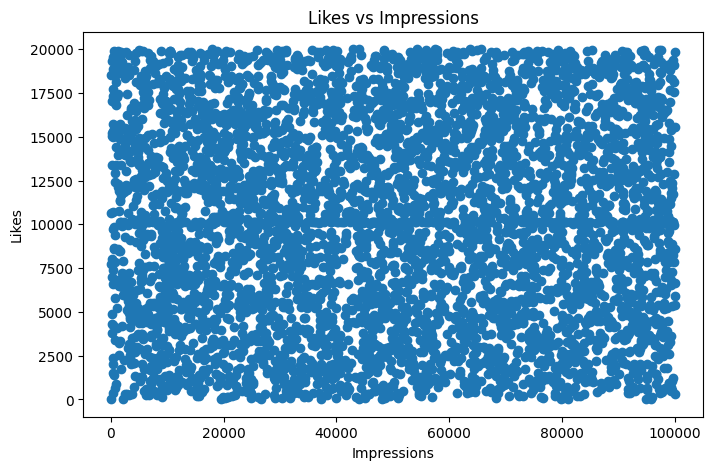

In [59]:
# A. Matplotlib
# Step 1: Scatter plot — Likes vs Impressions
plt.figure(figsize=(8, 5))

plt.scatter(df_clean['impression_count'], df_clean['likes'])

plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')

plt.show()

A scatter plot shows the relationship between impressions and likes.

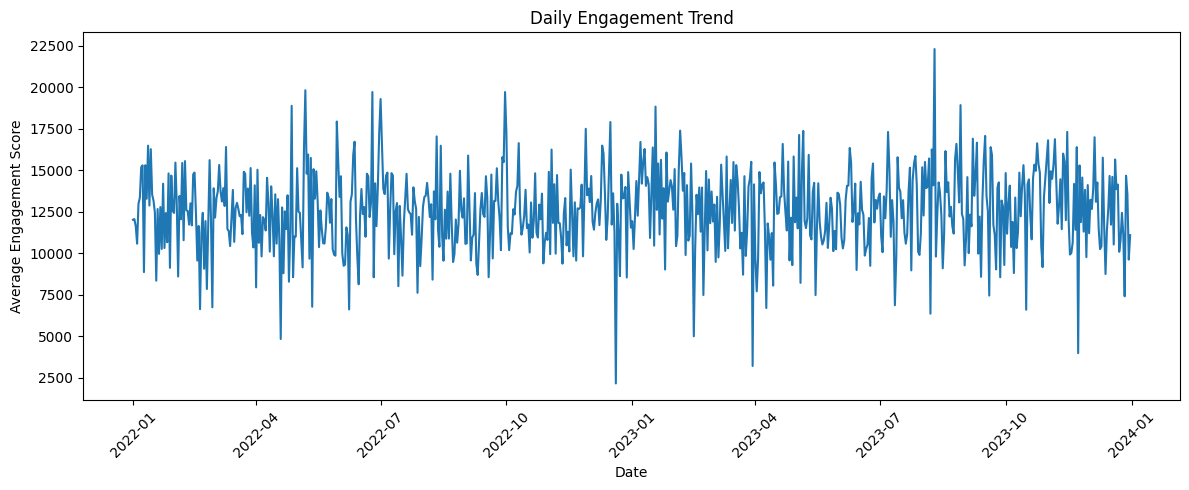

In [60]:
# Step 2: Line chart — Daily engagement trend
daily_engagement = df_clean.groupby(
    'posted_at'
)['engagement_score'].mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Shows how average engagement changes over time.

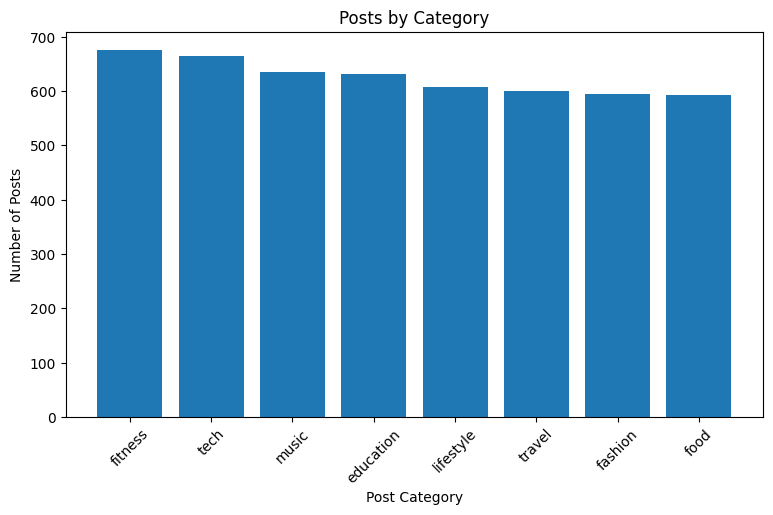

In [61]:
# Step 3: Bar chart — Posts by category
category_counts = df_clean['post_category'].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(category_counts.index, category_counts.values)

plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Posts by Category')

plt.xticks(rotation=45)
plt.show()

Compares the number of posts in each category.

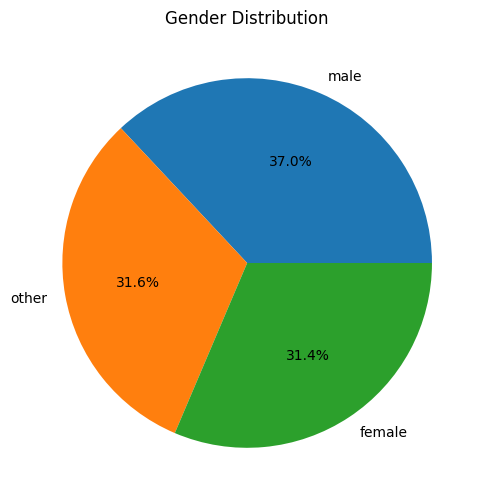

In [62]:
# Step 4: Pie chart — Gender distribution
gender_counts = df_clean['gender'].value_counts()

plt.figure(figsize=(6, 6))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

Shows the percentage distribution of genders.

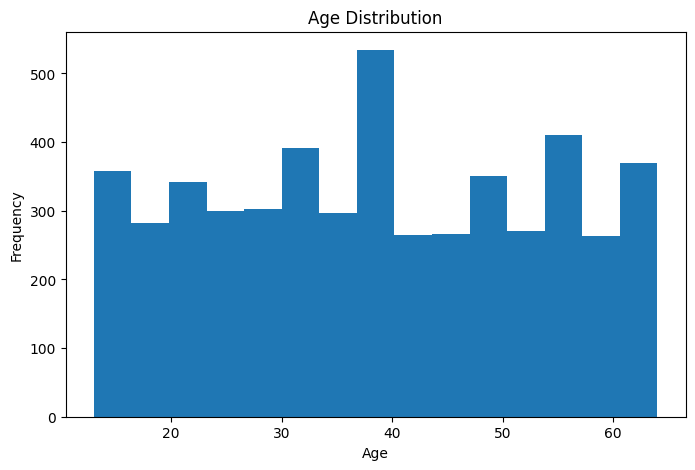

In [63]:
# Step 5: Histogram — Age distribution
plt.figure(figsize=(8, 5))

plt.hist(df_clean['age'], bins=15)

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')

plt.show()

Shows the distribution of users across different ages.

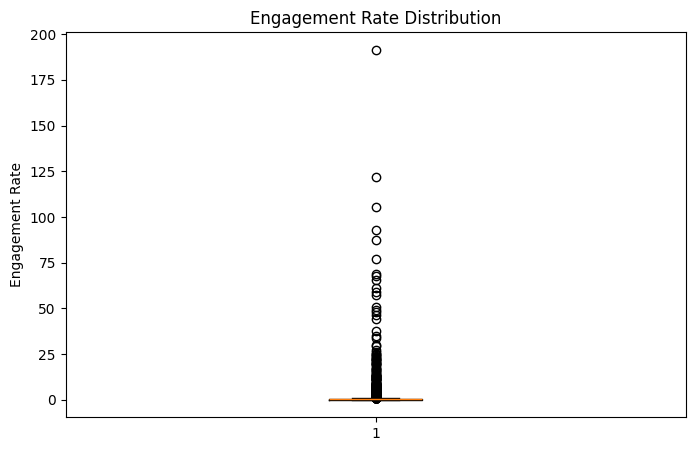

In [64]:
# Step 6: Box plot — Engagement rate
plt.figure(figsize=(8, 5))

plt.boxplot(df_clean['engagement_rate'].dropna())

plt.ylabel('Engagement Rate')
plt.title('Engagement Rate Distribution')

plt.show()

Displays the median, quartiles, and potential outliers in engagement rate.

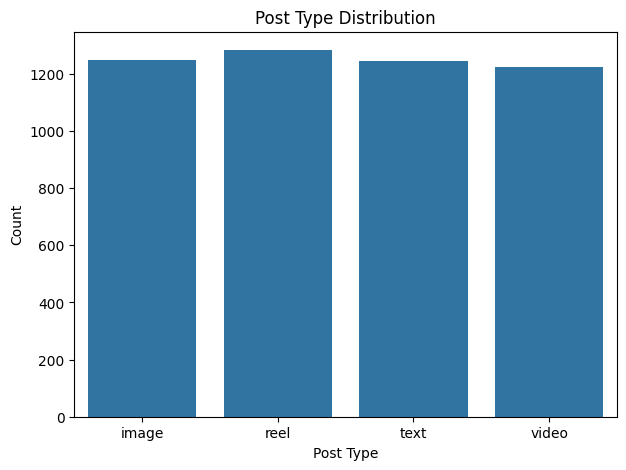

In [65]:
# B. Seaborn

# Step 7: Count plot — Post type
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='post_type')

plt.title('Post Type Distribution')
plt.xlabel('Post Type')
plt.ylabel('Count')

plt.show()

Shows the number of posts for each post type.

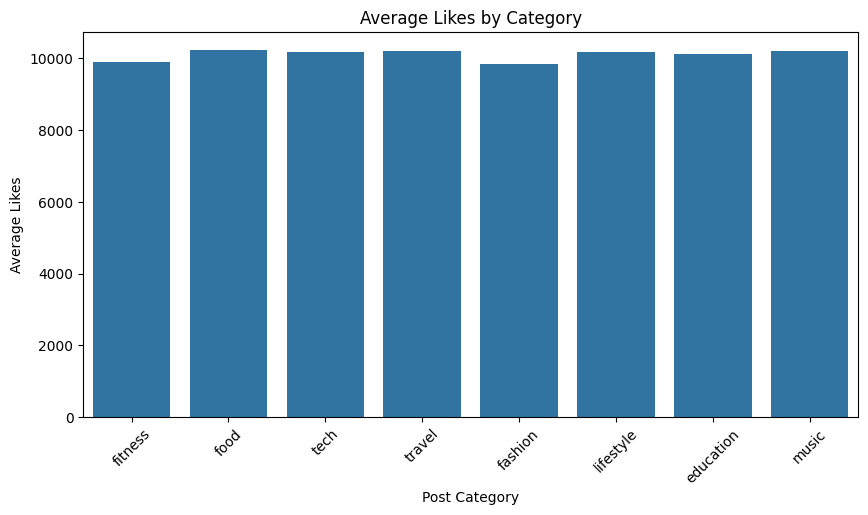

In [66]:
# Step 8: Bar plot — Average likes by category
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')

plt.xticks(rotation=45)
plt.show()

Compares average likes across different content categories.

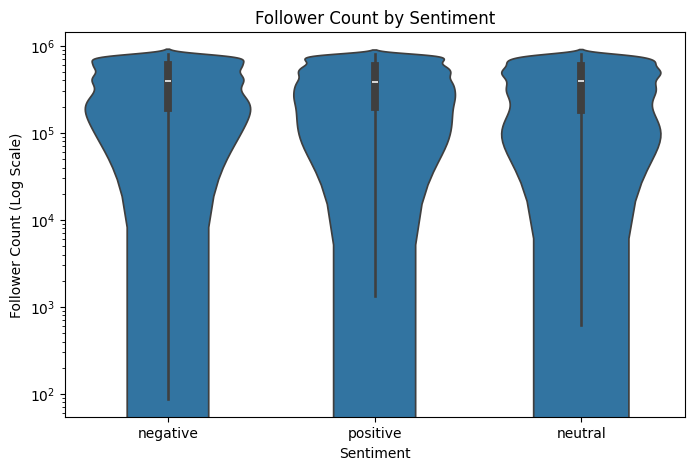

In [67]:
# Step 9: Violin plot — Followers vs Sentiment
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df_clean,
    x='sentiment',
    y='follower_count'
)

plt.yscale('log')

plt.title('Follower Count by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count (Log Scale)')

plt.show()

Shows the distribution of follower counts for each sentiment category.

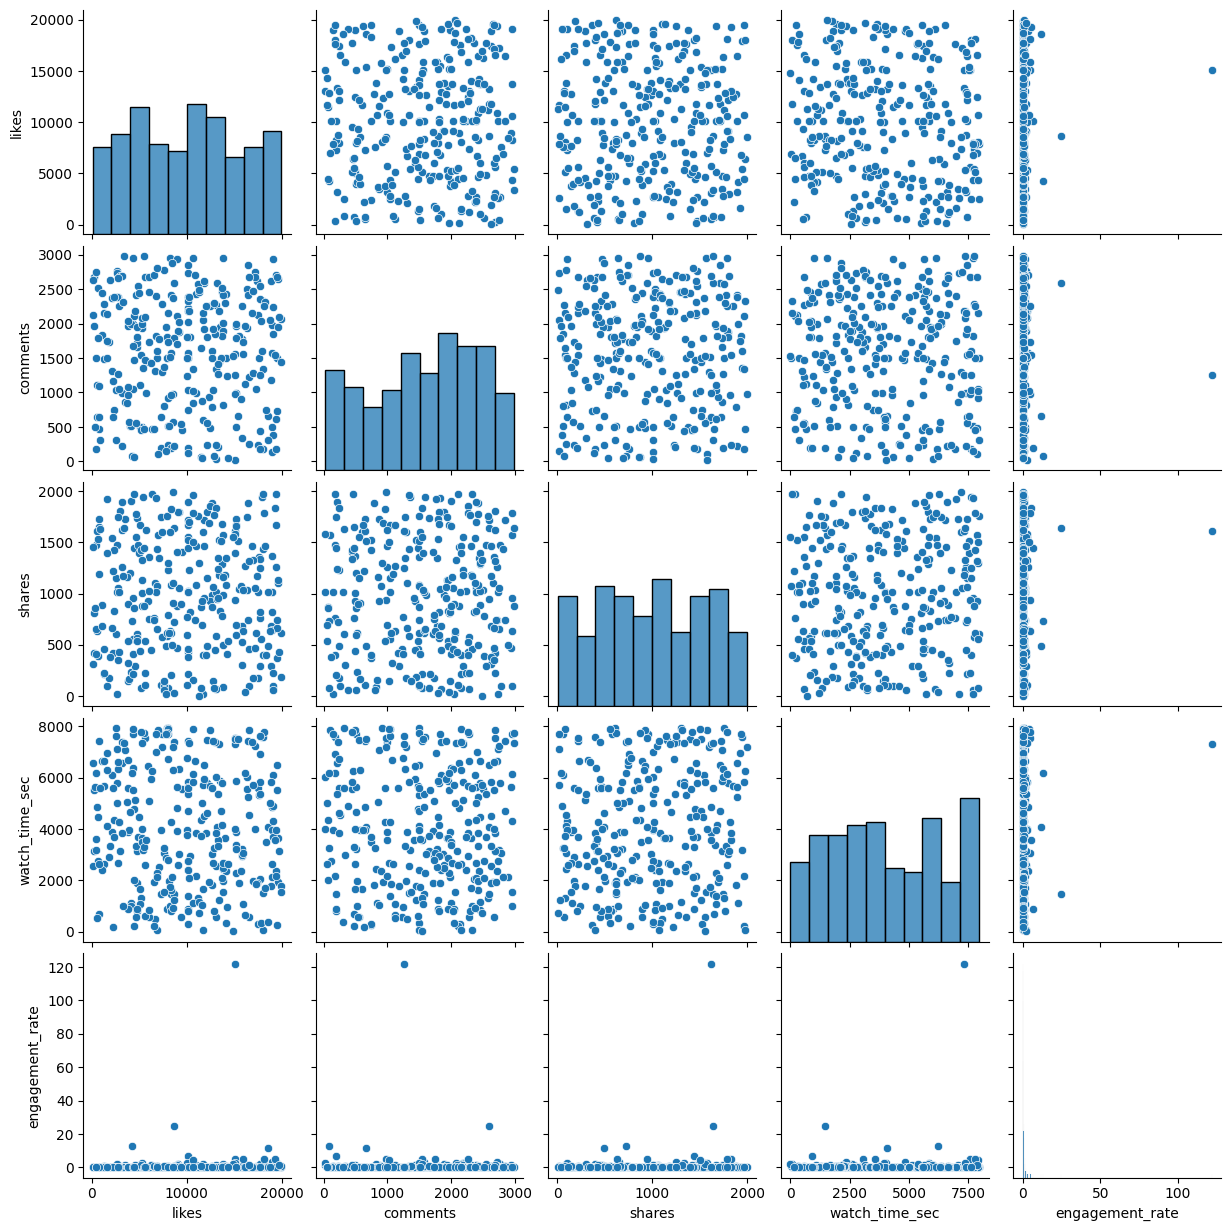

In [68]:
# Step 10: Pair plot — Numeric features
numeric_data = df_clean[
    ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate']
]

sample_data = numeric_data.sample(
    n=min(300, len(numeric_data)),
    random_state=42
)

sns.pairplot(sample_data)

plt.show()

Shows relationships between selected numerical variables. We use 300 records to keep the chart manageable.

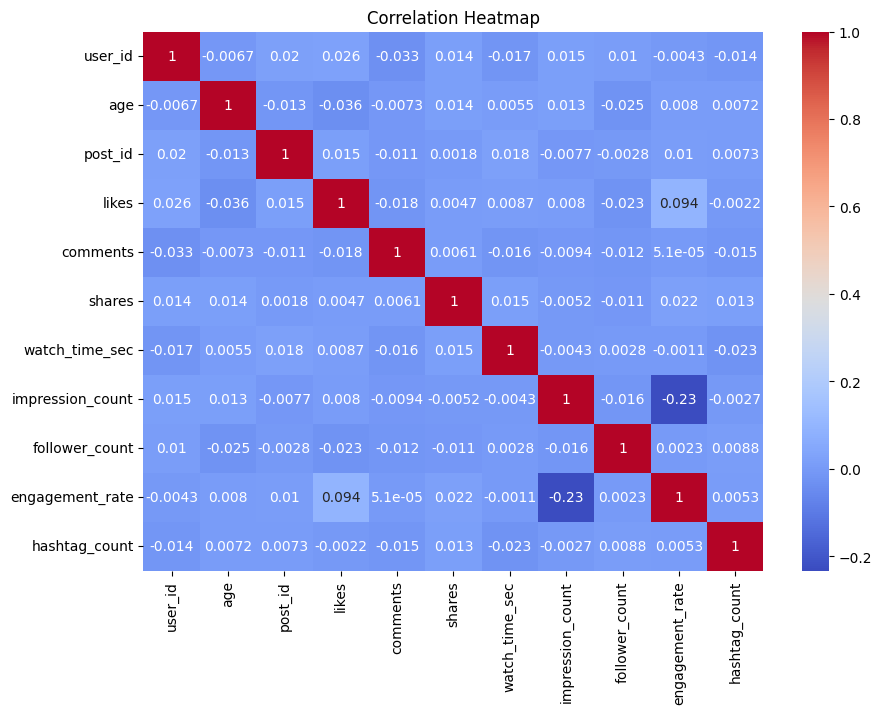

In [69]:
# Step 11: Heatmap — Correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

Displays correlations between numerical columns using different shades.

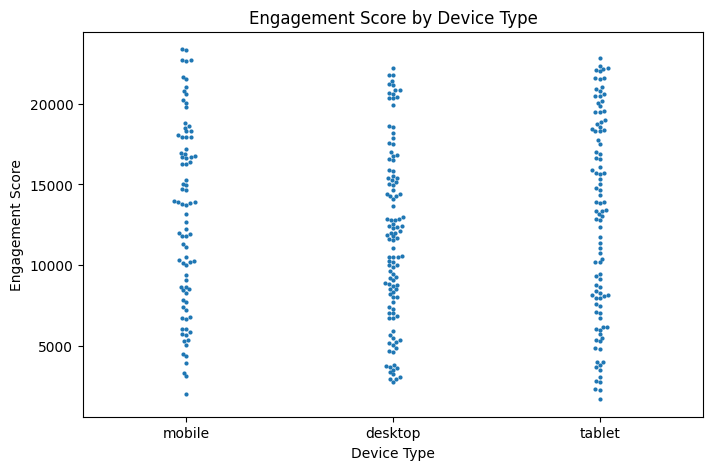

In [70]:
#Step 12: Swarm plot — Engagement vs Device
sample_data = df_clean.sample(
    n=min(300, len(df_clean)),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=sample_data,
    x='device_type',
    y='engagement_score',
    size=3
)

plt.title('Engagement Score by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')

plt.show()

Compares engagement scores across mobile, desktop, and tablet devices.

In [71]:
# C. Plotly — Interactive Visualization

# Step 13: Interactive line chart — Daily engagement
daily_data = df_clean.groupby(
    'posted_at',
    as_index=False
)['engagement_score'].mean()

fig = px.line(
    daily_data,
    x='posted_at',
    y='engagement_score',
    title='Interactive Daily Engagement Trend'
)

fig.show()




*   px.line() creates an interactive line chart
*   can hover over the chart to view values
*   can zoom in and out to explore the trend.




In [72]:
# Final Insights

# Step 1: Which post type has the highest engagement?
df_clean.groupby('post_type')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
post_type,
video,1.122365
text,1.064549
image,0.895646
reel,0.783047


Ranks post types according to average engagement rate.

In [73]:
# Step 2: Which content category performs best?
df_clean.groupby('post_category')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
post_category,
food,1.358628
tech,1.160475
lifestyle,1.091019
music,0.888803
fitness,0.865628
education,0.844222
fashion,0.807109
travel,0.702223


Identifies the category with the highest average engagement rate.

In [74]:
# Step 3: Which countries have the highest average engagement rate?
df_clean.groupby('country')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
country,
brazil,1.540704
australia,1.324339
france,1.146402
uae,1.112352
canada,0.916659
uk,0.850966
japan,0.769623
germany,0.759000
india,0.655005


Compares average engagement rates across countries.

In [75]:
# Step 4: How does age affect engagement?
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[12, 20, 30, 40, 50, 60, 100],
    labels=['13-20', '21-30', '31-40', '41-50', '51-60', '61+']
)

df_clean.groupby('age_group', observed=False)['engagement_rate'].mean()

,engagement_rate
age_group,
13-20,0.802733
21-30,1.018917
31-40,0.843572
41-50,1.103215
51-60,1.106470
61+,0.801381


Groups users by age and compares their average engagement rates.

In [76]:
# Step 5: Compare verified and unverified accounts
df_clean.groupby('is_verified').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

,likes,comments,shares,engagement_rate
is_verified,,,,
False,10137.201129,1505.511401,1001.599292,0.954744
True,9824.533126,1469.573499,1015.173913,1.054250


Compares average engagement metrics between verified and unverified accounts.

In [77]:
# Step 6: Find the best time of day for impressions
df_clean.groupby('posted_at')['impression_count'].mean().sort_values(
    ascending=False
)

,impression_count
posted_at,
2023-12-02,98263.5
2023-08-10,90304.5
2023-09-06,89909.0
2023-02-22,84897.0
2023-12-16,81594.0
...,...
2023-10-07,15330.0
2022-08-01,12526.0
2022-12-20,11483.0


Finds the dates with the highest average impressions. This is a daily analysis, not a time-of-day analysis.

In [78]:
# Step 7: Compare device type and watch time
df_clean.groupby('device_type')['watch_time_sec'].mean().sort_values(
    ascending=False
)

,watch_time_sec
device_type,
mobile,4087.830760
tablet,3979.736429
desktop,3974.792521


Identifies which device type has the highest average watch time.

In [79]:
# Step 8: Which sentiment performs best?
df_clean.groupby('sentiment')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
sentiment,
negative,1.038486
neutral,0.991170
positive,0.919744


Compares average engagement rates across positive, negative, and neutral posts.

In [80]:
# Step 9: Analyze negative and neutral sentiment posts
df_clean[df_clean['sentiment'].isin(['negative', 'neutral'])].groupby(
    'sentiment'
).agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
})

,likes,comments,shares,engagement_rate
sentiment,,,,
negative,10208.096875,1516.094792,1007.307292,1.038486
neutral,9923.194499,1528.404060,996.565160,0.991170


Compares likes, comments, shares, and engagement rates for negative and neutral posts.

Overall Summary

This project focuses on analysing social media engagement data using Python. The dataset contains 5,000 records and 19 columns, including user details, post types, likes, comments, shares, impressions, followers, and engagement rates.

The project uses Pandas and NumPy for data handling, cleaning, numerical calculations, and analysis. Missing values, duplicate records, incorrect data types, and inconsistent categories are checked and handled. Data exploration and statistical analysis are performed to understand engagement patterns and user behaviour.

Different visualisation libraries, including Matplotlib, Seaborn, and Plotly, are used to create charts and graphs. These visualisations help identify popular post types, successful content categories, audience engagement across countries, and the impact of devices and sentiment.

Overall, the project aims to understand social media engagement patterns, identify important trends, and generate useful insights from the dataset using Python.